# 0 — Data and replication baseline

Downloads and freezes the public Wisconsin LGPIF train/validation split used by the published study being extended, performs compact EDA, and reconstructs its no-LLM Gamma GLM baseline. Re-running this notebook is idempotent.

Sources: [paper/code](https://github.com/ganml/llmlgpif), [original data page](https://sites.google.com/view/doubleglm/home), [published article](https://variancejournal.org/article/162423-using-large-language-models-to-generate-new-features-from-text-data-for-loss-prediction).

**Paper coverage:** §3.1, Tables 1–2 (data), and the no-LLM row of Table 3.

Use the pinned environment in [README.md](README.md#run-the-analysis). Run cells from top to bottom; saved inference caches allow reproduction without API keys or new requests.


In [ ]:
from pathlib import Path
from IPython.display import display
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
import hashlib, requests

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "s0_get_data.ipynb").exists()), Path.cwd())
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
TABLES = ROOT / "tables"
FIGURES = ROOT / "figures"
for folder in (RAW, PROCESSED, TABLES, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

FILES = {
    "peril.training.csv": {
        "id": "1or4r3fz62rFWhuXqXROIv0JSM6t7-ZWQ",
        "sha256": "8592694291bc9cbdce5bd2a33683c5ca961e6db45937830955f180ff3e8e1cc5",
    },
    "peril.validation.csv": {
        "id": "1g4eSftMYO3lbTZ38usWEvI-zLoyjHQls",
        "sha256": "7734dfd42d51dec22c5b063e53032f7c62143729c9980b4f74028ab738f45653",
    },
}

for name, spec in FILES.items():
    path = RAW / name
    if not path.exists():
        url = f"https://drive.usercontent.google.com/download?id={spec['id']}&export=download&confirm=t"
        response = requests.get(url, timeout=120)
        response.raise_for_status()
        path.write_bytes(response.content)
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    if digest != spec["sha256"]:
        raise ValueError(f"Checksum mismatch for {name}: {digest}")

train = pd.read_csv(RAW / "peril.training.csv")
valid = pd.read_csv(RAW / "peril.validation.csv")
PERILS = ["Vandalism", "Fire", "Lightning", "Wind", "Hail", "Vehicle", "WaterNW", "WaterW", "Misc"]

def prepare(frame, split):
    out = frame.copy()
    out["Description"] = out["Description"].fillna("").astype(str).str.strip()
    out["description_id"] = out["Description"].map(lambda x: "d_" + hashlib.sha256(x.encode()).hexdigest()[:16])
    out["split"] = split
    out["claim_type"] = out[PERILS].idxmax(axis=1)
    out["log_loss"] = np.log1p(out["Loss"])
    return out

train = prepare(train, "train")
valid = prepare(valid, "validation")
claims = pd.concat([train, valid], ignore_index=True)
descriptions = claims[["description_id", "Description"]].drop_duplicates().sort_values("description_id").reset_index(drop=True)

assert claims["description_id"].nunique() == len(descriptions)
assert not descriptions["description_id"].duplicated().any()
claims.to_csv(PROCESSED / "claims.csv", index=False)
descriptions.to_csv(PROCESSED / "descriptions.csv", index=False)

summary = pd.DataFrame({
    "split": ["train", "validation", "combined"],
    "claims": [len(train), len(valid), len(claims)],
    "unique_descriptions": [train.description_id.nunique(), valid.description_id.nunique(), claims.description_id.nunique()],
    "median_loss": [train.Loss.median(), valid.Loss.median(), claims.Loss.median()],
    "mean_loss": [train.Loss.mean(), valid.Loss.mean(), claims.Loss.mean()],
    "empty_descriptions": [(train.Description == "").sum(), (valid.Description == "").sum(), (claims.Description == "").sum()],
})
summary.to_csv(TABLES / "data_summary.csv", index=False)
display(summary.round(2))


,split,claims,unique_descriptions,median_loss,mean_loss,empty_descriptions
0,train,4991,3733,2243.28,19297.05,0
1,validation,1039,996,3240.00,21488.37,0
2,combined,6030,4690,2392.01,19674.63,0


## Compact EDA

Loss is extremely right-skewed, which motivates the paper's `log1p` transformation. The figure retains the frozen train/validation split and shows the mix of claim types.

**Reports:** §3.1; exploratory figure (not included in the paper).


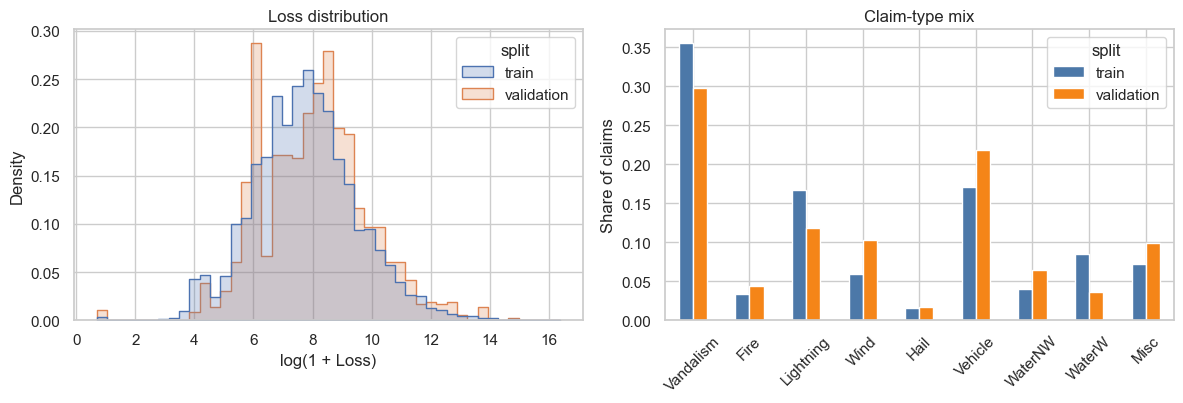

In [2]:
sns.set_theme(style="whitegrid", context="notebook")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.histplot(data=claims, x="log_loss", hue="split", bins=45, element="step", stat="density", common_norm=False, ax=axes[0])
axes[0].set(xlabel="log(1 + Loss)", title="Loss distribution")
mix = pd.crosstab(claims["claim_type"], claims["split"], normalize="columns").reindex(PERILS)
mix.plot(kind="bar", ax=axes[1], color=["#4C78A8", "#F58518"])
axes[1].set(xlabel="", ylabel="Share of claims", title="Claim-type mix")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(FIGURES / "data_overview.png", dpi=180, bbox_inches="tight")
plt.show()


## Baseline replication

The published specification models `log1p(Loss)` with a Gamma GLM and log link. Eight peril indicators enter the design matrix; `Misc` is the reference category. The metrics below should reproduce Table 10's no-LLM row (validation R² 0.3398 and MAE 1.0694).

**Reports:** §3.1; Table 3, no-LLM baseline.


In [3]:
FEATURES = PERILS[:-1]
X_train = sm.add_constant(train[FEATURES], has_constant="add")
X_valid = sm.add_constant(valid[FEATURES], has_constant="add")
fit = sm.GLM(
    train["log_loss"],
    X_train,
    family=sm.families.Gamma(link=sm.families.links.Log()),
).fit()

def metrics(y, pred, p):
    y = np.asarray(y)
    pred = np.asarray(pred)
    r2 = 1 - np.square(y - pred).sum() / np.square(y - y.mean()).sum()
    return {
        "r2": r2,
        "adjusted_r2": 1 - (1 - r2) * (len(y) - 1) / (len(y) - p - 1),
        "mae": np.abs(y - pred).mean(),
    }

baseline = pd.DataFrame([
    {"model": "No LLM feature", "run": 0, "split": "train", **metrics(train.log_loss, fit.predict(X_train), len(FEATURES))},
    {"model": "No LLM feature", "run": 0, "split": "validation", **metrics(valid.log_loss, fit.predict(X_valid), len(FEATURES))},
])
baseline.to_csv(TABLES / "baseline_performance.csv", index=False)

published = {"r2": 0.3398, "adjusted_r2": 0.3347, "mae": 1.0694}
observed = baseline.query("split == 'validation'").iloc[0]
for metric, target in published.items():
    assert abs(observed[metric] - target) < 5e-5, f"{metric} did not reproduce: {observed[metric]} vs {target}"

display(baseline.round(4))
print(f"Frozen {len(claims):,} claims and {len(descriptions):,} unique descriptions.")


,model,run,split,r2,adjusted_r2,mae
0,No LLM feature,0,train,0.3742,0.3732,1.0585
1,No LLM feature,0,validation,0.3398,0.3347,1.0694


Frozen 6,030 claims and 4,690 unique descriptions.


The checksum assertions freeze the source files, while the metric assertions act as a regression test for the downstream specification. Notebook 1 can now classify the unique descriptions without changing the original split or model.
